# Translate MDL files to python 

@Author: Georgia 
@Last Date: 2024-05/06

This notebook is designed to translate MDL files to Python. The goal is to create a script that can automatically convert Causal Loop Diagrams into Adjacency Matrixs which can then be used for network anlaysis. 

A causal loop diagram (CLD) is a visual representation of the causal relationships between variables in a system. It is commonly used in system dynamics modeling to understand the feedback loops and dynamics of a complex system.

To achieve this, we will need to extract the necessary information from the MDL file, including the variables, their relationships, and the polarity of the relationships. We can then use this information to construct an adjacency matrix and a polarity matrix, which can be further analyzed using network analysis techniques.

In this example, I will show a basic exmple of an rabbit population CLD, and the translation to the matrixs.
There is one reinforcing loop and one balancing loop in this CLD. Note there is a link between food and rabbit population without a defined polarity. 

 
![Example Image](Testing/rabbit_cld.png)

We will turn this CLD into 3 three objects: 
1. Dict_vars: A dictionary of vairiable names and their index. 
2. Adj_matrix: An adjacency matrix that represents the connections between variables
3. Pol_matrix: A polarity matrix that represents the polarity of the connections



# Import library

In [131]:
import pandas as pd
import numpy as np
import regex as re
import networkx as nx

In [87]:
import parse_cld 

# Read txt file of MDL file

In [88]:
with open('Testing/rabbit_example.mdl', 'r') as f:
    lines = f.readlines()
    
# Compile regex to match line with sketch info    

start_pattern = re.compile(r"\\\---///*") 
end_pattern = re.compile(r'\/{3}-+\\{3}')
                         
extracted = []
extract = False

for line in lines:
    if end_pattern.search(line):
        # Stop extracting if end pattern found
        extract = False

    elif start_pattern.search(line):
        # Start new extraction
        extracted = []
        extract = True

    elif extract:
        # Append to extracted lines
        extracted.append(line)

extracted = extracted[3:]
print(extracted)


['10,1,rabbit population,371,246,44,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '10,2,birth,532,268,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,3,1,2,1,0,43,0,0,192,0,-1--1--1,,1|(482,217)|\n', '1,4,2,1,1,0,43,0,0,192,0,-1--1--1,,1|(451,312)|\n', '10,5,deaths,203,245,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,6,1,5,1,0,43,0,0,192,0,-1--1--1,,1|(293,206)|\n', '1,7,5,1,1,0,45,0,0,192,0,-1--1--1,,1|(270,280)|\n', '10,8,food,418,148,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,9,8,1,0,0,0,0,0,192,0,-1--1--1,,1|(0,0)|\n', '10,10,fox population,330,362,61,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,11,1,10,1,0,0,0,0,192,0,-1--1--1,,1|(331,320)|\n', '10,12,numbers of hunts,170,420,44,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,13,10,12,1,0,43,0,0,192,0,-1--1--1,,1|(265,402)|\n']


In [154]:
df = pd.DataFrame(extracted)
df = df[0].str.split(',', expand = True)
# change column 0 dytpe to int
df[0] = df[0].astype(int)

# Grab dependencies 
df_links = df.loc[df[0]==1,  ]
df_links = df_links[[0,1, 2,3,6]]
df_links = df_links.rename(columns={0: 'variable type', 1: 'index',2: 'from', 3: 'to', 6: 'polarity'})
df_links['polarity'] = df_links['polarity'].astype(int)
df_links['links'] = 1
# In Column 6, it depicts, the polarity sign, 43 is positive, 45 is negative, and other values are unknown.

df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1,
                                     np.where(df_links['polarity'] == 45, -1, 3))

    
# df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1, -1)
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


In [90]:
# check datatype of df 
# for cols in df.columns:
#     print(df[cols].dtype)
#     

In [91]:
df_vars = df.loc[df[0]==10,  ]
# Create a dictionary based on  dataframe column 1 and 2
dict_var = df_vars.set_index(1)[2].to_dict()
dict_var


{'1': 'rabbit population',
 '2': 'birth',
 '5': 'deaths',
 '8': 'food',
 '10': 'fox population',
 '12': 'numbers of hunts'}

In [92]:
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


# Adjacency matrix: 

link_matrix[2: rabbit population] = 1 means that there is an arrow goes from birth to rabbit population. 

In [159]:
# Make an adjacency matrix and polarity matrix from df_links column from, to and links 
link_matrix = df_links.pivot(index='from', columns='to', values='links').fillna(0).astype(int)

In [160]:
link_matrix

to,1,10,12,2,5
from,,,,,
1,0,1,0,1,1
10,0,0,1,0,0
2,1,0,0,0,0
5,1,0,0,0,0
8,1,0,0,0,0


In [161]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(link_matrix.index) - set(link_matrix.columns)
missing_rows = set(link_matrix.columns) - set(link_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        link_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        link_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
link_matrix = link_matrix.sort_index(axis=1)
link_matrix = link_matrix.sort_index(axis = 0)
# link_matrix

In [96]:
# link_matrix.columns = link_matrix.columns.map(dict_var)
link_matrix

to,rabbit population,fox population,numbers of hunts,birth,deaths,food
from,,,,,,
1,0,1,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,1,0,0,0,0,0
8,1,0,0,0,0,0


In [134]:
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


In [149]:
# create a dict of d
dict_links

/var/folders/sg/c6q1bz_d6s5fwn637scs4f3c0000gs/T/ipykernel_89798/4063872156.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dict_links = df_links.groupby('from').apply(lambda x : pd.DataFrame(zip(x['to'], x['polarity_type']), columns=['to', 'polarity_type'])).to_dict()


{'to': {('1', 0): '2',
  ('1', 1): '5',
  ('1', 2): '10',
  ('10', 0): '12',
  ('2', 0): '1',
  ('5', 0): '1',
  ('8', 0): '1'},
 'polarity_type': {('1', 0): 1,
  ('1', 1): 1,
  ('1', 2): 3,
  ('10', 0): 1,
  ('2', 0): 1,
  ('5', 0): -1,
  ('8', 0): 3}}

In [157]:
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


In [198]:
df_subset = df_links[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

# df_links.groupby('from').apply(lambda x: x.set_index('to').to_dict(orient='index'), include_groups=False).to_dict()
d = df_subset.groupby('from').apply(lambda x: x.set_index('to').to_dict(orient='index'), include_groups=False).to_dict()




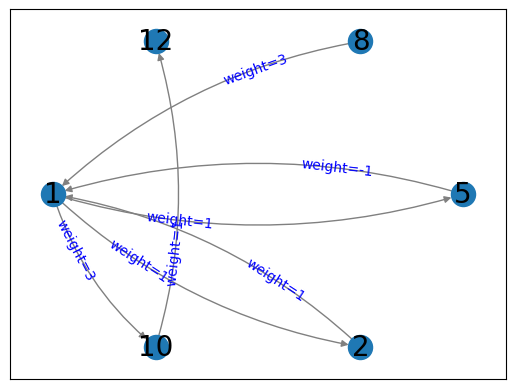

In [199]:
G_test = nx.MultiDiGraph(d)
draw_labeled_multigraph(G_test, "weight")



In [156]:
df_links.groupby('from').apply(lambda x: x.set_index('to').to_dict(orient='index'), include_groups=False).to_dict()
dict_links = df_links.set_index('from').to_dict()['to']
dict_links



{'1': '10', '2': '1', '5': '1', '8': '1', '10': '12'}

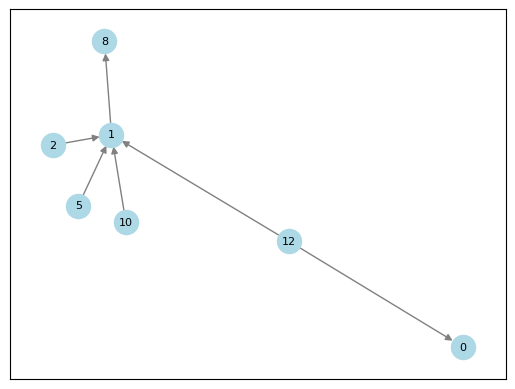

In [152]:

G3= nx.to_networkx_graph(dict_links, create_using=nx.MultiDiGraph())
nx.draw_networkx(G3, with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)


In [141]:
dict_links

{'1': '10', '2': '1', '5': '1', '8': '1', '10': '12'}

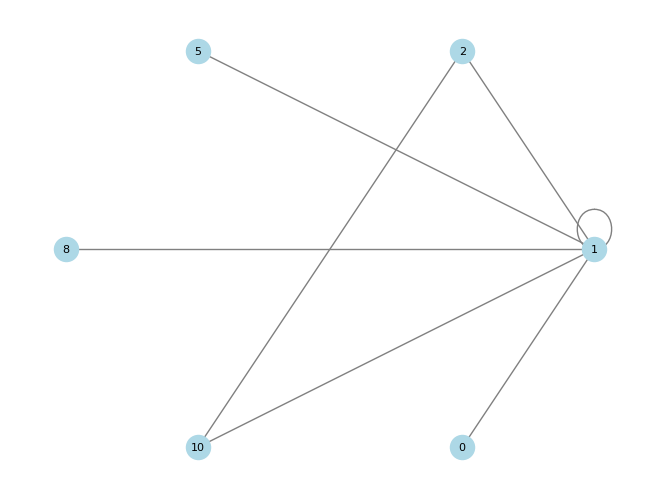

In [140]:
# Get adjancecy link in a dictionary format


G = nx.from_dict_of_lists(dict_links)
nx.draw(G, pos=nx.circular_layout(G), with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)

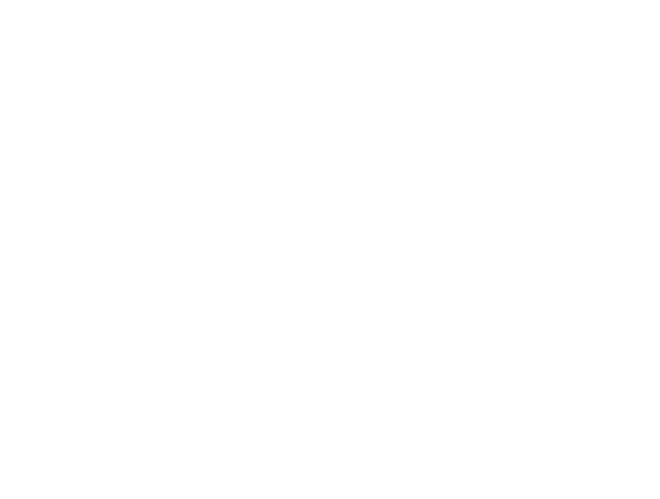

In [139]:
G = nx.MultiDiGraph()

dicts_of_dicts = nx.to_dict_of_dicts(G)
G2 = nx.from_dict_of_dicts(dicts_of_dicts, create_using= nx.MultiDiGraph, multigraph_input= True)

nx.draw(G2, pos=nx.circular_layout(G), with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)

In [183]:
import networkx as nx

# Create a MultiDiGraph
G = nx.MultiDiGraph()

# Add nodes
G.add_node(1)
G.add_node(2)
G.add_node(3)

# Add edges - note that multiple edges can be added between the same nodes
G.add_edge(1, 2, weight=5)
G.add_edge(2, 1, weight=3)
G.add_edge(2, 3, weight=4)

# Display the nodes and edges
print("Nodes of the graph:")
print(G.nodes(data=True))

print("\nEdges of the graph:")
print(G.edges(data=True))

# Access specific edge data
print("\nWeight of the first edge between node 1 and 2:")
print(G.get_edge_data(1, 2, key=0))  # 'key' is used to distinguish between multiple edges
print("test", G[1][2])
print(G.adj)
# nx.draw_networkx(G, arrows= None,pos=nx.circular_layout(G), with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)
# edges = nx.draw_networkx_edges(G, pos=nx.spring_layout(G))
# edge_labels = nx.draw_networkx_edge_labels(G, pos=nx.spring_layout(G))
# edge_labels

Nodes of the graph:
[(1, {}), (2, {}), (3, {})]

Edges of the graph:
[(1, 2, {'weight': 5}), (2, 1, {'weight': 3}), (2, 3, {'weight': 4})]

Weight of the first edge between node 1 and 2:
{'weight': 5}
test {0: {'weight': 5}}
{1: {2: {0: {'weight': 5}}}, 2: {1: {0: {'weight': 3}}, 3: {0: {'weight': 4}}}, 3: {}}


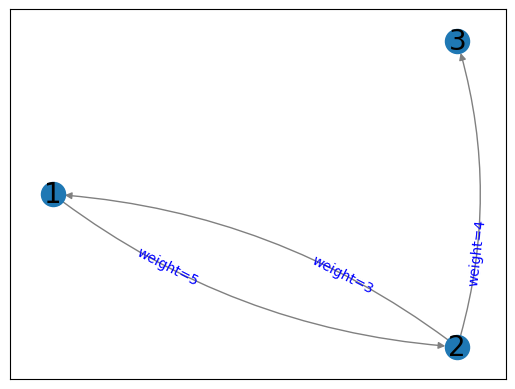

In [180]:
import itertools as it
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


def draw_labeled_multigraph(G, attr_name, ax=None):
    """
    Length of connectionstyle must be at least that of a maximum number of edges
    between pair of nodes. This number is maximum one-sided connections
    for directed graph and maximum total connections for undirected graph.
    """
    # Works with arc3 and angle3 connectionstyles
    connectionstyle = [f"arc3,rad={r}" for r in it.accumulate([0.15] * 4)]
    # connectionstyle = [f"angle3,angleA={r}" for r in it.accumulate([30] * 4)]

    pos = nx.shell_layout(G)
    nx.draw_networkx_nodes(G, pos, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=20, ax=ax)
    nx.draw_networkx_edges(
        G, pos, edge_color="grey", connectionstyle=connectionstyle, ax=ax
    )

    labels = {
        tuple(edge): f"{attr_name}={attrs[attr_name]}"
        for *edge, attrs in G.edges(keys=True, data=True)
    }
    nx.draw_networkx_edge_labels(
        G,
        pos,
        labels,
        connectionstyle=connectionstyle,
        label_pos=0.3,
        font_color="blue",
        bbox={"alpha": 0},
        ax=ax,
    )


# nodes = "ABC"
# prod = list(it.product(nodes, repeat=2))
# pair_dict = {f"Product x {i}": prod * i for i in range(1, 5)}

draw_labeled_multigraph(G, "weight")

# fig, axes = plt.subplots(2, 2)
# for (name, pairs), ax in zip(pair_dict.items(), np.ravel(axes)):
#     G = nx.MultiDiGraph()
#     for i, (u, v) in enumerate(pairs):
#         G.add_edge(u, v, w=round(i / 3, 2))
#     draw_labeled_multigraph(G, "w", ax)
#     ax.set_title(name)
# fig.tight_layout()
# plt.show()


# Polarity matrix: 

link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population
link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population. 
. 

In [97]:
polarity_matrix = df_links.pivot(index='from', columns = 'to', values = 'polarity_type').fillna(0).astype(int)


In [98]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(polarity_matrix.index) - set(polarity_matrix.columns)
missing_rows = set(polarity_matrix.columns) - set(polarity_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        polarity_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        polarity_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
polarity_matrix = polarity_matrix.sort_index(axis=1)
polarity_matrix = polarity_matrix.sort_index(axis = 0)
polarity_matrix

to,1,10,12,2,5,8
from,,,,,,
1,0,3,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,-1,0,0,0,0,0
8,3,0,0,0,0,0


In [23]:
polarity_matrix.columns = polarity_matrix.columns.map(dict_var)

polarity_matrix

to,rabbit population,fox population,numbers of hunts,birth,deaths,food
from,,,,,,
1,0,3,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,-1,0,0,0,0,0
8,3,0,0,0,0,0


# Store in NetworkX

In [82]:
link_matrix
# Write this matrix as a pd code



to,1,10,12,2,5,8
from,,,,,,
1,0,1,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,1,0,0,0,0,0
8,1,0,0,0,0,0


In [77]:
# adjacency_list = {}
# 
# for source, target in link_matrix.iterrows(): 
#     if source in adjacency_list:
#         target = target.tolist()
# 
#         adjacency_list[source].append(target)
#     else: 
#         target = target.tolist()
#         adjacency_list[source] = target

# print(adjacency_list)



In [78]:
# print(adjacency_list)


{'1': [0, 1, 0, 1, 1, 0], '10': [0, 0, 1, 0, 0, 0], '12': [0, 0, 0, 0, 0, 0], '2': [1, 0, 0, 0, 0, 0], '5': [1, 0, 0, 0, 0, 0], '8': [1, 0, 0, 0, 0, 0]}


In [58]:
# parse_cld.df_to_adjacency_list(link_matrix)

AttributeError: 'Series' object has no attribute 'append'

In [67]:
for i, j in link_matrix.iterrows():
    # turn j as a list instead of a pandas series
    j = j.tolist()
    print(j)
    # print(j.dtype)

[0, 1, 0, 1, 1, 0]
[0, 0, 1, 0, 0, 0]
[0, 0, 0, 0, 0, 0]
[1, 0, 0, 0, 0, 0]
[1, 0, 0, 0, 0, 0]
[1, 0, 0, 0, 0, 0]


In [103]:
polarity_matrix

to,1,10,12,2,5,8
from,,,,,,
1,0,3,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,-1,0,0,0,0,0
8,3,0,0,0,0,0


In [125]:
import networkx as nx 
G_polar = nx.from_pandas_adjacency(polarity_matrix)

In [128]:

G_polar
# Get attributes from G_polar
node_attributes = dict(G_polar.nodes(data=True))

node_attributes

{'1': {}, '10': {}, '12': {}, '2': {}, '5': {}, '8': {}}

In [124]:
G = nx.from_pandas_adjacency(link_matrix)


NetworkXError: ('Columns must match Indices.', "['2', '5', '12', '10', '8', '1'] not in columns")

In [120]:
df_nodes = pd.DataFrame({'node_id': ['1', '2', '5'], 'attribute1': ['A', 
                                                              'B', 'C']})

G.add_nodes_from((n, dict(d)) for n, d in df_nodes.iterrows())


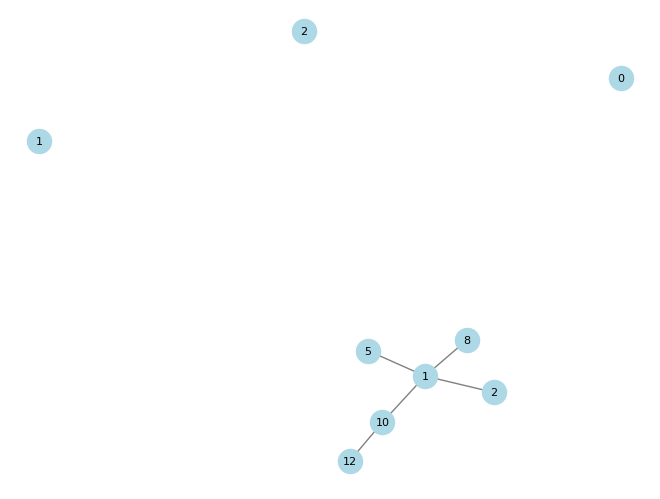

In [121]:
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)

{'1': {'10': True, '2': True, '5': True, '8': True},
 '10': {'1': True, '12': True},
 '12': {'10': True},
 '2': {'1': True},
 '5': {'1': True},
 '8': {'1': True}}

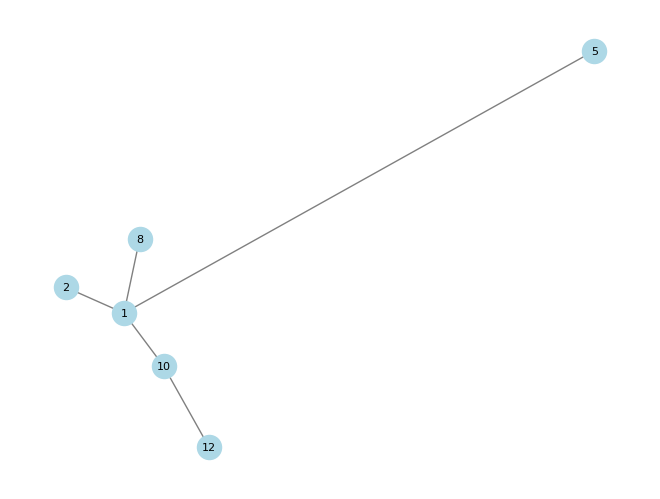

In [115]:
# Visualize the network graph
nx.draw(G_polar, with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)

test_dic = nx.to_dict_of_lists(G_polar)
test_dic

test_dict_1 = nx.to_dict_of_dicts(G_polar, edge_data=True)
test_dict_1

{'1': {'10': {'weight': 1},
  '2': {'weight': 1},
  '5': {'weight': 1},
  '8': {'weight': 1}},
 '10': {'1': {'weight': 1}, '12': {'weight': 1}},
 '12': {'10': {'weight': 1}},
 '2': {'1': {'weight': 1}},
 '5': {'1': {'weight': 1}},
 '8': {'1': {'weight': 1}}}

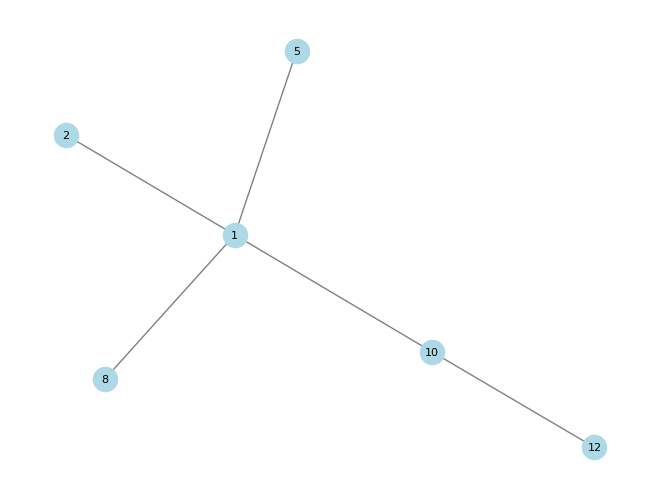

In [106]:
# Visualize the network graph
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', font_size=8)

test_dic = nx.to_dict_of_lists(G)
test_dic

test_dict_1 = nx.to_dict_of_dicts(G)#, edge_data=True)
test_dict_1